# Music Genre Classification using CNN

This notebook classifies music tracks into 10 genres using a Convolutional Neural Network (CNN) trained on mel-spectrogram representations of audio from the **GTZAN** dataset.

**Pipeline:** Load audio → segment into 3s clips → extract mel-spectrograms → train CNN → evaluate.

In [32]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, BatchNormalization,
                                     Dropout, Flatten, Dense, Input)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow version: 2.20.0
GPU available: True


In [33]:
# ── Configuration ──────────────────────────────────────────────
DATA_PATH = "/path/to/gtzan/Data/genres_original"
GENRES = ["blues", "classical", "country", "disco", "hiphop",
          "jazz", "metal", "pop", "reggae", "rock"]

SAMPLE_RATE = 22050
SEGMENT_DURATION = 5        # seconds (increased from 3 for more context)
SAMPLES_PER_SEGMENT = SAMPLE_RATE * SEGMENT_DURATION  # 110250
N_MELS = 128
HOP_LENGTH = 512
N_FFT = 2048

IMAGES_DIR = os.path.join("..", "Images")
os.makedirs(IMAGES_DIR, exist_ok=True)

## Data Loading

Each 30-second audio clip is split into 3-second segments. For each segment a mel-spectrogram is computed and stored along with the genre label and the originating track index (used later for a leak-free train/test split).

In [34]:
def load_data(data_path, genres, sr=SAMPLE_RATE, segment_duration=SEGMENT_DURATION,
              n_mels=N_MELS, hop_length=HOP_LENGTH, n_fft=N_FFT):
    """Load audio files, segment them, and extract mel-spectrograms."""
    samples_per_segment = sr * segment_duration
    spectrograms, labels, track_ids = [], [], []
    track_counter = 0
    skipped = []

    for genre in genres:
        genre_dir = os.path.join(data_path, genre)
        if not os.path.isdir(genre_dir):
            print(f"WARNING: directory not found – {genre_dir}")
            continue

        files = sorted([f for f in os.listdir(genre_dir) if f.endswith(".wav")])
        for fname in files:
            filepath = os.path.join(genre_dir, fname)
            try:
                y, _ = librosa.load(filepath, sr=sr)
            except Exception as e:
                skipped.append((filepath, str(e)))
                track_counter += 1
                continue

            num_segments = len(y) // samples_per_segment
            for s in range(num_segments):
                start = s * samples_per_segment
                segment = y[start:start + samples_per_segment]

                mel = librosa.feature.melspectrogram(
                    y=segment, sr=sr, n_mels=n_mels,
                    hop_length=hop_length, n_fft=n_fft
                )
                mel_db = librosa.power_to_db(mel, ref=np.max)
                spectrograms.append(mel_db)
                labels.append(genre)
                track_ids.append(track_counter)

            track_counter += 1

    if skipped:
        print(f"Skipped {len(skipped)} file(s):")
        for path, err in skipped:
            print(f"  {path}: {err}")

    return np.array(spectrograms), np.array(labels), np.array(track_ids)


spectrograms, labels, track_ids = load_data(DATA_PATH, GENRES)
print(f"Spectrograms shape: {spectrograms.shape}")
print(f"Labels shape:       {labels.shape}")
print(f"Unique tracks:      {len(np.unique(track_ids))}")

Skipped 1 file(s):
  /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original/jazz/jazz.00054.wav: 
Spectrograms shape: (5985, 128, 216)
Labels shape:       (5985,)
Unique tracks:      999


## Exploratory Data Analysis

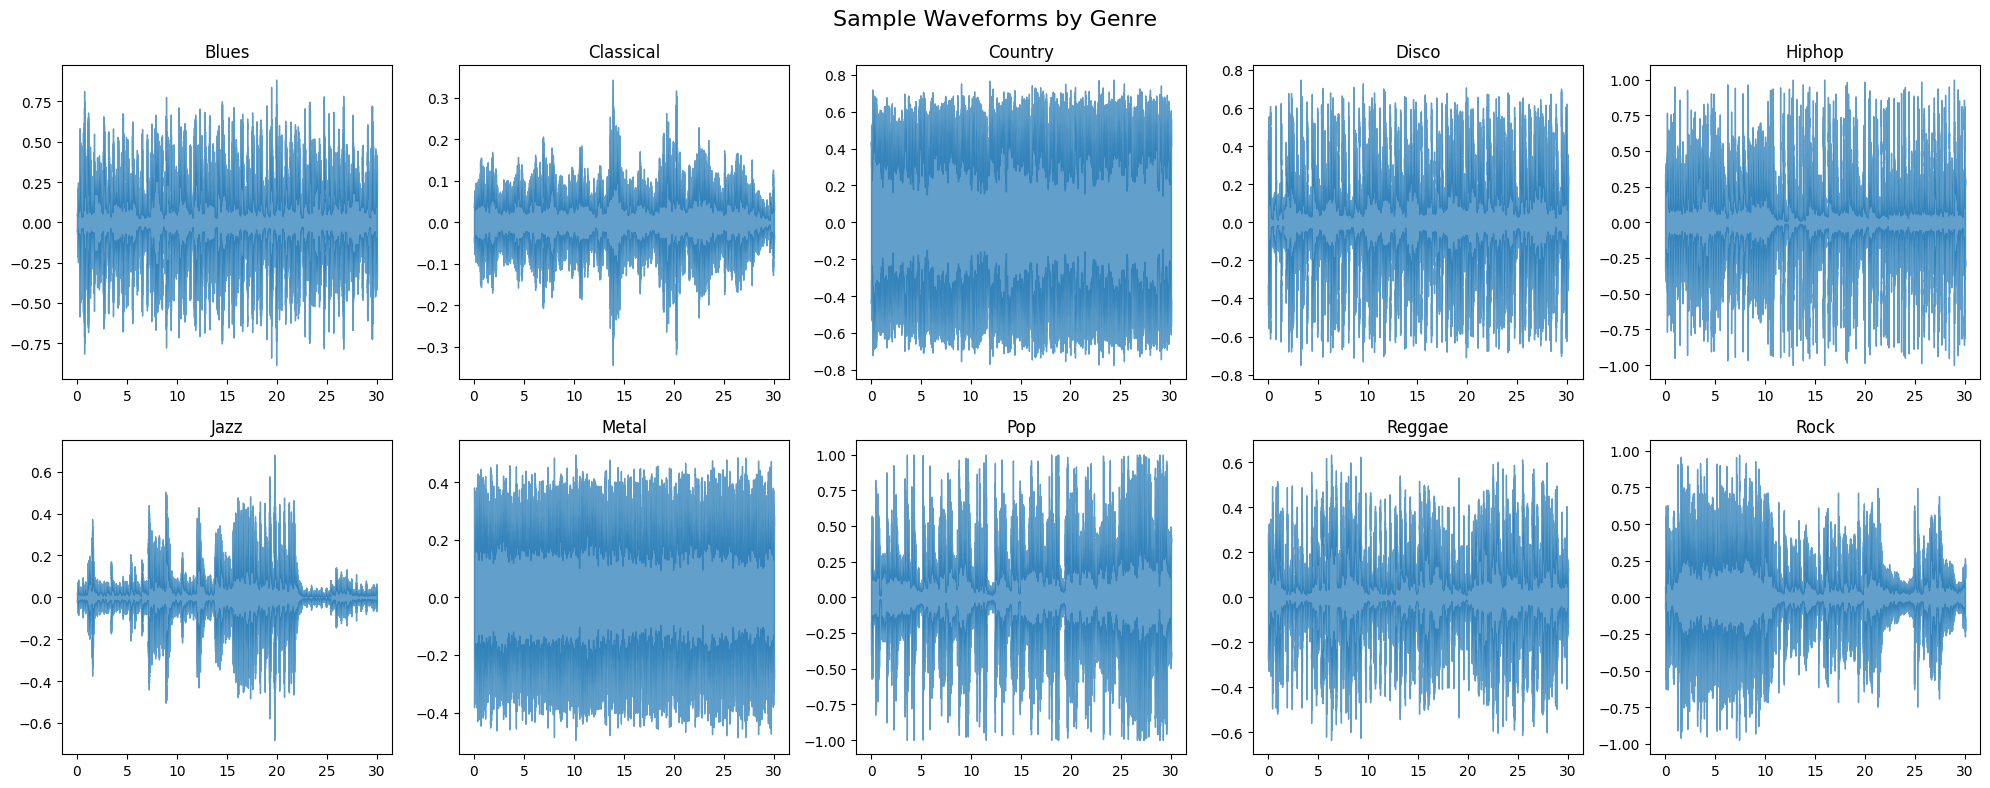

In [35]:
# Plot one sample waveform per genre
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle("Sample Waveforms by Genre", fontsize=16)

for idx, genre in enumerate(GENRES):
    genre_dir = os.path.join(DATA_PATH, genre)
    sample_file = sorted([f for f in os.listdir(genre_dir) if f.endswith(".wav")])[0]
    y, sr_ = librosa.load(os.path.join(genre_dir, sample_file), sr=SAMPLE_RATE)
    ax = axes[idx // 5, idx % 5]
    librosa.display.waveshow(y, sr=sr_, ax=ax, alpha=0.7)
    ax.set_title(genre.capitalize())
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "waveforms.png"), dpi=150, bbox_inches="tight")
plt.show()

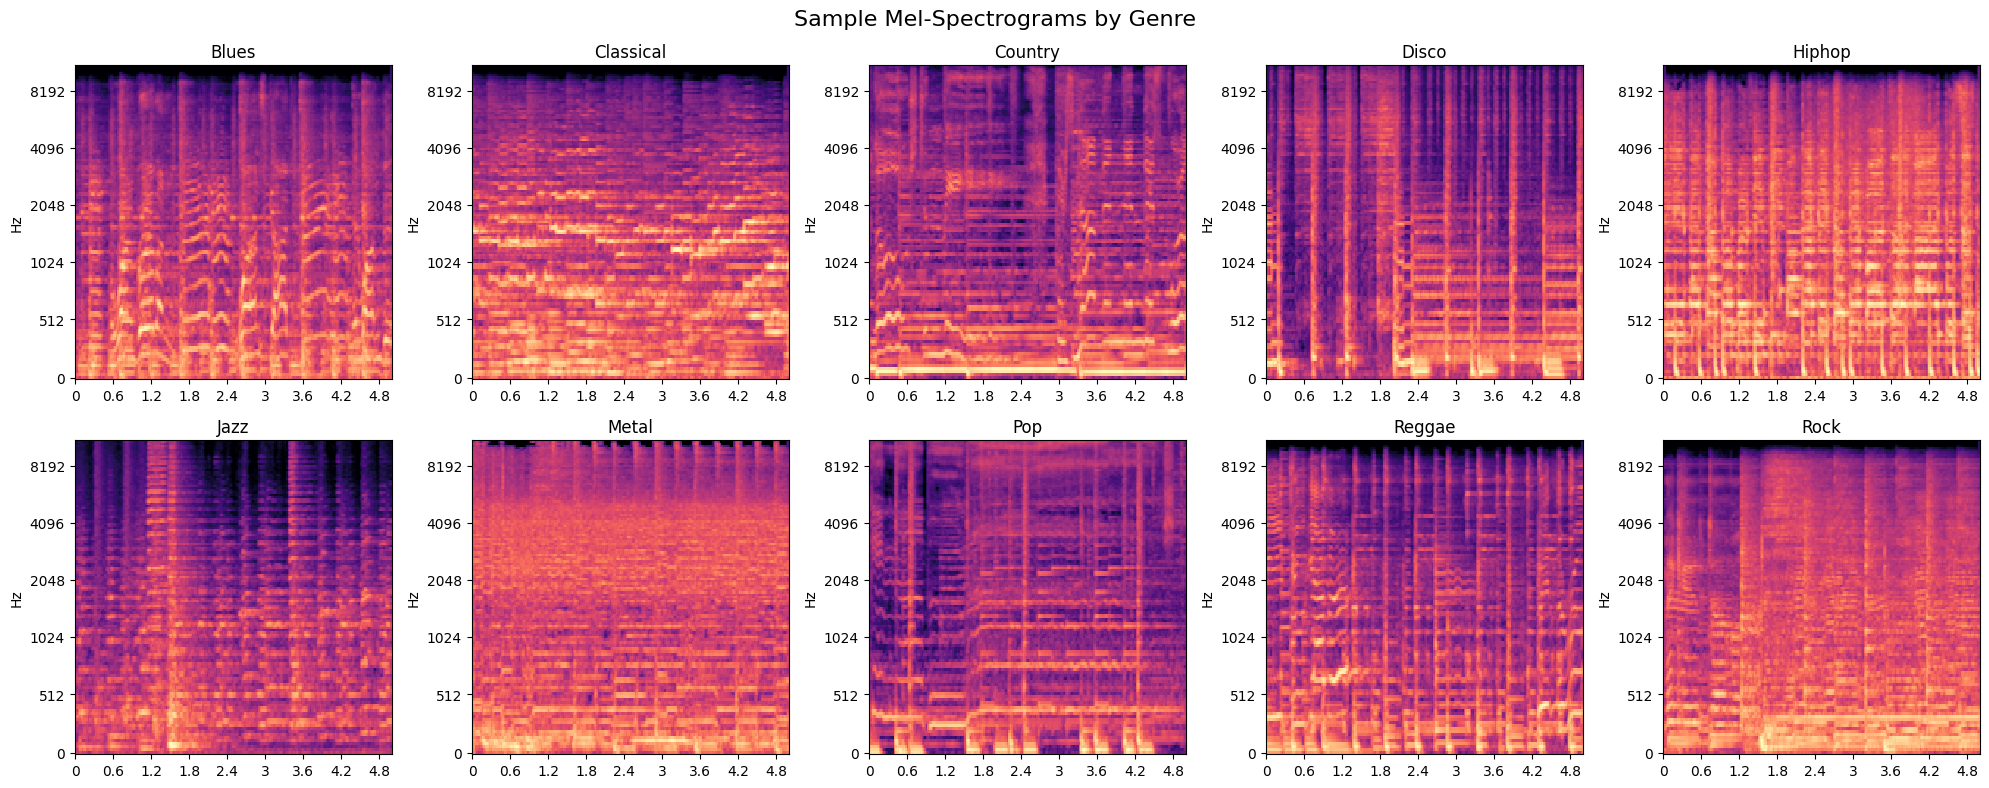

In [36]:
# Plot one sample mel-spectrogram per genre
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle("Sample Mel-Spectrograms by Genre", fontsize=16)

for idx, genre in enumerate(GENRES):
    mask = labels == genre
    sample_spec = spectrograms[mask][0]
    ax = axes[idx // 5, idx % 5]
    img = librosa.display.specshow(
        sample_spec, sr=SAMPLE_RATE, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", ax=ax
    )
    ax.set_title(genre.capitalize())
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "spectrograms.png"), dpi=150, bbox_inches="tight")
plt.show()

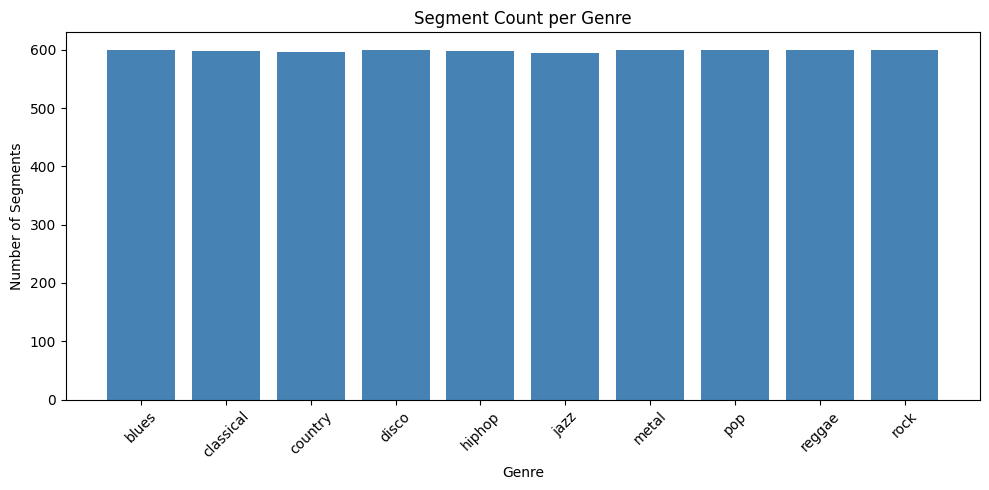

In [37]:
# Genre distribution
unique, counts = np.unique(labels, return_counts=True)
plt.figure(figsize=(10, 5))
plt.bar(unique, counts, color="steelblue")
plt.title("Segment Count per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Segments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "genre_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

## Train / Validation / Test Split (70/15/15 by track)

The split is performed **by track**, not by segment, so that segments from the same 30-second clip never appear in both training, validation, and test sets (avoids data leakage at every stage). Validation data is passed explicitly to `model.fit()` instead of using Keras `validation_split`.

In [38]:
# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(labels)

# Build a per-track label array for stratified splitting
unique_tracks = np.unique(track_ids)
track_label_map = {t: y_encoded[track_ids == t][0] for t in unique_tracks}
track_labels = np.array([track_label_map[t] for t in unique_tracks])

# First split: 70% train, 30% temp (will become 15% val + 15% test)
train_tracks, temp_tracks, train_tlabels, temp_tlabels = train_test_split(
    unique_tracks, track_labels, test_size=0.3, random_state=42, stratify=track_labels
)

# Second split: 50/50 on temp → 15% val, 15% test
val_tracks, test_tracks = train_test_split(
    temp_tracks, test_size=0.5, random_state=42, stratify=temp_tlabels
)

train_mask = np.isin(track_ids, train_tracks)
val_mask = np.isin(track_ids, val_tracks)
test_mask = np.isin(track_ids, test_tracks)

X_train, y_train = spectrograms[train_mask], y_encoded[train_mask]
X_val, y_val = spectrograms[val_mask], y_encoded[val_mask]
X_test, y_test = spectrograms[test_mask], y_encoded[test_mask]

# Min-max normalize to [0, 1] using train set bounds
train_min = X_train.min()
train_max = X_train.max()
X_train = (X_train - train_min) / (train_max - train_min)
X_val = (X_val - train_min) / (train_max - train_min)
X_test = (X_test - train_min) / (train_max - train_min)

# Add channel dimension for Conv2D
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}  y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}  y_test:  {y_test.shape}")
print(f"\nTrain tracks: {len(train_tracks)}, Val tracks: {len(val_tracks)}, Test tracks: {len(test_tracks)}")
print(f"Normalization — min: {train_min:.2f}, max: {train_max:.2f}")

X_train: (4186, 128, 216, 1)  y_train: (4186,)
X_val:   (900, 128, 216, 1)  y_val:   (900,)
X_test:  (899, 128, 216, 1)  y_test:  (899,)

Train tracks: 699, Val tracks: 150, Test tracks: 150
Normalization — min: -80.00, max: 0.00


## Model Architecture

A four-block CNN with increasing filter depth (32 → 64 → 128 → 256), batch normalisation, max-pooling, and dropout, followed by fully-connected layers. **SpecAugment** (random frequency and time masking) is applied during training for data augmentation.

In [39]:
input_shape = X_train.shape[1:]  # (n_mels, time_steps, 1)

# SpecAugment: randomly mask frequency bands and time steps during training
def spec_augment(x):
    freq_mask_param = 20
    time_mask_param = 30
    # Frequency masking
    f = tf.random.uniform([], 0, freq_mask_param, dtype=tf.int32)
    f0 = tf.random.uniform([], 0, tf.shape(x)[0] - f, dtype=tf.int32)
    mask = tf.concat([tf.ones([f0, tf.shape(x)[1], 1]),
                      tf.zeros([f, tf.shape(x)[1], 1]),
                      tf.ones([tf.shape(x)[0] - f0 - f, tf.shape(x)[1], 1])], axis=0)
    x = x * mask
    # Time masking
    t = tf.random.uniform([], 0, time_mask_param, dtype=tf.int32)
    t0 = tf.random.uniform([], 0, tf.shape(x)[1] - t, dtype=tf.int32)
    mask = tf.concat([tf.ones([tf.shape(x)[0], t0, 1]),
                      tf.zeros([tf.shape(x)[0], t, 1]),
                      tf.ones([tf.shape(x)[0], tf.shape(x)[1] - t0 - t, 1])], axis=1)
    x = x * mask
    return x

# Build training dataset with SpecAugment
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train)).map(
    lambda x, y: (spec_augment(x), y), num_parallel_calls=tf.data.AUTOTUNE
).batch(32).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(32).prefetch(tf.data.AUTOTUNE)

model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation="relu", padding="same", kernel_initializer="he_normal",
           input_shape=input_shape),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Block 2
    Conv2D(64, (3, 3), activation="relu", padding="same", kernel_initializer="he_normal"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Block 3
    Conv2D(128, (3, 3), activation="relu", padding="same", kernel_initializer="he_normal"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Block 4
    Conv2D(256, (3, 3), activation="relu", padding="same", kernel_initializer="he_normal"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Classifier
    Flatten(),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.3),
    Dense(256, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.3),
    Dense(len(GENRES), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 216, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 216, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 108, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 108, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 54, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 54, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 27, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 27, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 13, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 13, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 26624)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │    13,632,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,155,658 (54.00 MB)

 Trainable params: 14,154,698 (54.00 MB)

 Non-trainable params: 960 (3.75 KB)

## Training

In [47]:
early_stop = EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.6753 - loss: 0.9277 - val_accuracy: 0.6578 - val_loss: 1.1636 - learning_rate: 6.2500e-05
Epoch 2/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.6971 - loss: 0.8853 - val_accuracy: 0.6222 - val_loss: 1.2334 - learning_rate: 6.2500e-05
Epoch 3/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.7054 - loss: 0.8602 - val_accuracy: 0.6344 - val_loss: 1.1875 - learning_rate: 6.2500e-05
Epoch 4/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.6980 - loss: 0.8612 - val_accuracy: 0.6611 - val_loss: 1.1207 - learning_rate: 6.2500e-05
Epoch 5/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.7069 - loss: 0.8449 - val_accuracy: 0.6633 - val_loss: 1.1239 - learning_rate: 6.2500e-05
Epoch 6/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.7198 - loss: 0.8033 - val_accuracy: 0.6611 - val_loss: 1.2046 - learning_rate: 6.2500e-05
Epoch 7/50
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - acc

## Evaluation

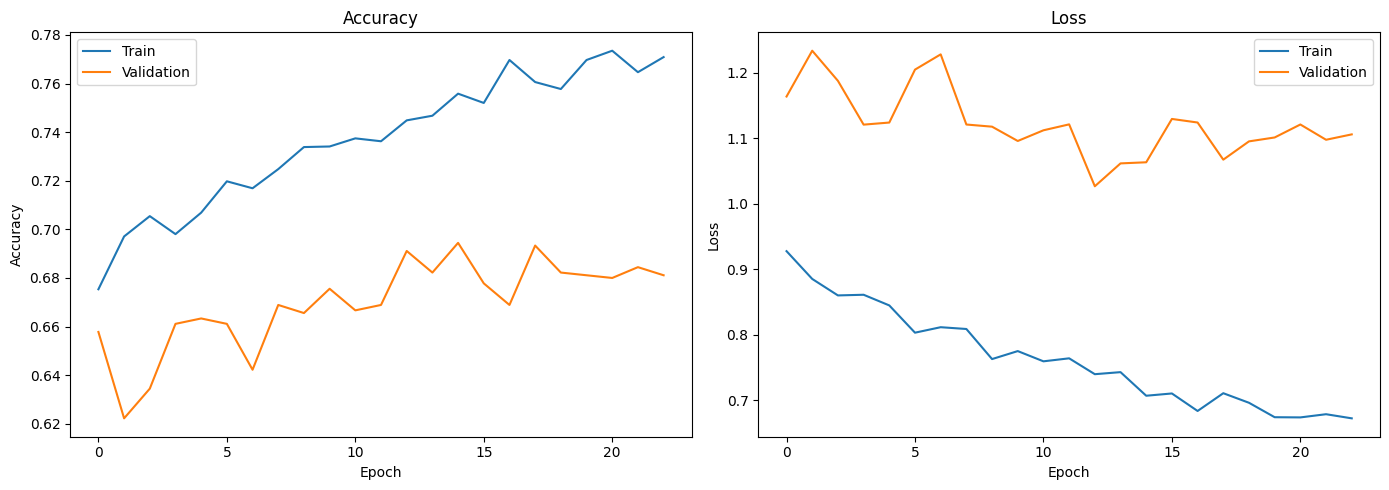

In [48]:
# Accuracy and loss curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history["accuracy"], label="Train")
ax1.plot(history.history["val_accuracy"], label="Validation")
ax1.set_title("Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(history.history["loss"], label="Train")
ax2.plot(history.history["val_loss"], label="Validation")
ax2.set_title("Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Segment-level Test Accuracy: 0.6841
Track-level Test Accuracy (majority vote): 0.7067


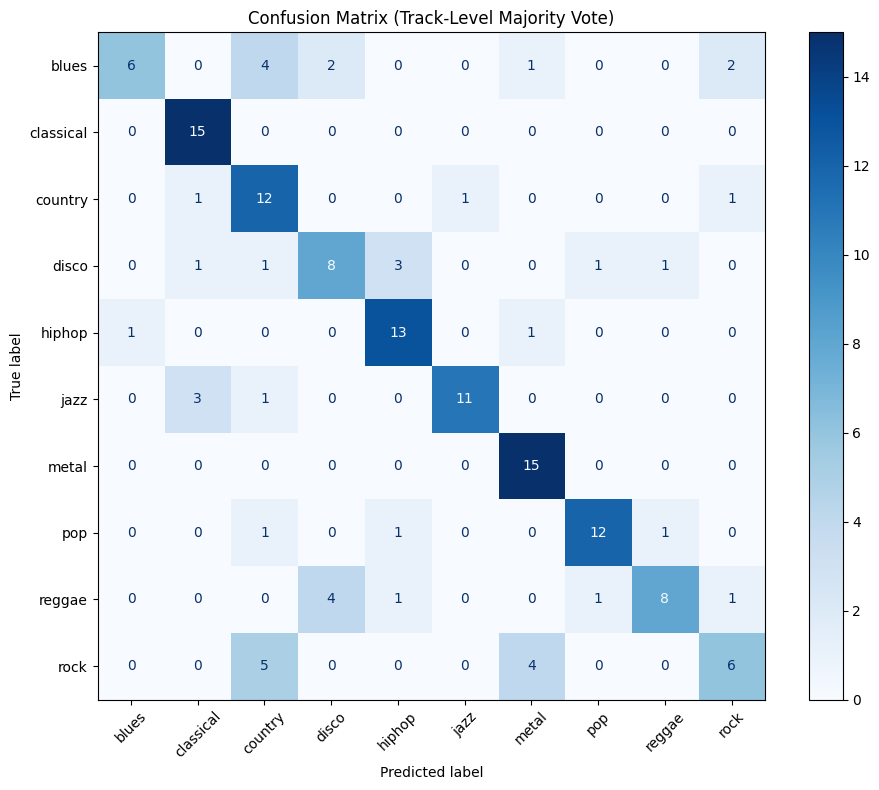

In [49]:
# Segment-level predictions
y_pred = np.argmax(model.predict(X_test), axis=1)

# ── Track-level majority voting ──
test_track_ids = track_ids[test_mask]
unique_test_tracks = np.unique(test_track_ids)

track_true, track_pred = [], []
for t in unique_test_tracks:
    t_mask = test_track_ids == t
    true_label = y_test[t_mask][0]
    seg_preds = y_pred[t_mask]
    voted_pred = np.bincount(seg_preds, minlength=len(GENRES)).argmax()
    track_true.append(true_label)
    track_pred.append(voted_pred)

track_true = np.array(track_true)
track_pred = np.array(track_pred)
track_acc = np.mean(track_true == track_pred)

print(f"Segment-level Test Accuracy: {np.mean(y_test == y_pred):.4f}")
print(f"Track-level Test Accuracy (majority vote): {track_acc:.4f}")

# Confusion matrix (track-level)
cm = confusion_matrix(track_true, track_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
ax.set_title("Confusion Matrix (Track-Level Majority Vote)")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

In [50]:
print("Classification Report (Track-Level Majority Vote):\n")
print(classification_report(track_true, track_pred, target_names=le.classes_))

Classification Report (Track-Level Majority Vote):

              precision    recall  f1-score   support

       blues       0.86      0.40      0.55        15
   classical       0.75      1.00      0.86        15
     country       0.50      0.80      0.62        15
       disco       0.57      0.53      0.55        15
      hiphop       0.72      0.87      0.79        15
        jazz       0.92      0.73      0.81        15
       metal       0.71      1.00      0.83        15
         pop       0.86      0.80      0.83        15
      reggae       0.80      0.53      0.64        15
        rock       0.60      0.40      0.48        15

    accuracy                           0.71       150
   macro avg       0.73      0.71      0.70       150
weighted avg       0.73      0.71      0.70       150



In [53]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Segment-level Test Accuracy: {test_acc:.4f}")
print(f"Segment-level Test Loss:     {test_loss:.4f}")
print(f"Track-level Test Accuracy:   {track_acc:.4f}")

Segment-level Test Accuracy: 0.6841
Segment-level Test Loss:     1.1343
Track-level Test Accuracy:   0.7067


In [54]:
model.save("music_genre_cnn-1.h5")
print("Model saved to music_genre_cnn-1.h5")

Model saved to music_genre_cnn-1.h5


## Conclusion

A CNN trained on 3-second mel-spectrogram segments from the GTZAN dataset can classify music into 10 genres with reasonable accuracy. Key observations:

- **Track-level splitting** prevents data leakage that would inflate reported accuracy.
- Genres like **classical** and **metal** are typically easier to distinguish; **rock** and **country** are often confused.
- The GTZAN dataset is small and has known labelling issues, so results should be interpreted with that in mind.

Possible improvements: data augmentation (time-stretch, pitch-shift), using MFCC features alongside mel-spectrograms, or switching to a pre-trained audio model.